In [23]:
from hydra import Hydra, SparseScaler
from sklearn.linear_model import RidgeClassifierCV
import re
import pandas as pd
from pathlib import Path
import numpy as np

In [24]:
DATA_FOLDER = Path("../dataset/cleaned")

# gets all the dfs from the cleaned folder into a dictionary
def get_dfs(folder=DATA_FOLDER, **read_kwargs):

    # retrieving dfs
    data = {
        path.stem: pd.read_csv(path, **read_kwargs)
        for path in sorted(Path(folder).glob("*.csv"))
    }

    # prints all loaded df names for overview
    print(f"Loaded {len(data)} datasets:")
    for name, df in data.items():
        print(f"  {name}: {df.shape}")

    # creade a dic for later renaming of all datasets 
    # to however each of us wants to
    namedic = {name: name for name in data}

    # returning dics
    return data, namedic

In [25]:
datasets, namedic = get_dfs()


Loaded 7 datasets:
  Iisingintie1: (75465, 14)
  Iisingintie2: (75465, 14)
  Iisingintie3: (114684, 14)
  Sinetänsalmentie1: (6426, 14)
  Sinetänsalmentie2: (7665, 14)
  Sinetänsalmentie3: (9222, 14)
  Sinetänsalmentie4: (18128, 14)


In [26]:
namedic

{'Iisingintie1': 'Iisingintie1',
 'Iisingintie2': 'Iisingintie2',
 'Iisingintie3': 'Iisingintie3',
 'Sinetänsalmentie1': 'Sinetänsalmentie1',
 'Sinetänsalmentie2': 'Sinetänsalmentie2',
 'Sinetänsalmentie3': 'Sinetänsalmentie3',
 'Sinetänsalmentie4': 'Sinetänsalmentie4'}

In [27]:
namedic["Iisingintie1"] = "df_i1"
namedic["Iisingintie2"] = "df_i2"
namedic["Iisingintie3"] = "df_i3"
namedic["Sinetänsalmentie1"] = "df_s1"
namedic["Sinetänsalmentie2"] = "df_s2"
namedic["Sinetänsalmentie3"] = "df_s3"
namedic["Sinetänsalmentie4"] = "df_s4"

datasets = {namedic.get(name, name): df for name, df in datasets.items()}
globals().update(datasets)


In [28]:
for name in datasets:
    print(f'{name} = datasets["{name}"]')

df_i1 = datasets["df_i1"]
df_i2 = datasets["df_i2"]
df_i3 = datasets["df_i3"]
df_s1 = datasets["df_s1"]
df_s2 = datasets["df_s2"]
df_s3 = datasets["df_s3"]
df_s4 = datasets["df_s4"]


In [29]:
df_i1 = datasets["df_i1"]
df_i2 = datasets["df_i2"]
df_i3 = datasets["df_i3"]
df_s1 = datasets["df_s1"]
df_s2 = datasets["df_s2"]
df_s3 = datasets["df_s3"]
df_s4 = datasets["df_s4"]

In [30]:
def make_panels(dfs, size, target_column, mode="time", distance_col="Loc(m)",
                channels_first=True, drop_cols=["Loc(m)", "Timer(ms)"]):
    # dfs: dict of dfs



    # size: either rows (time mode) or metres (distance mode)
    # target_column: Frostbumps, or sth else if you changed it 
    # mode: "time"  or "distance"
    # Claude Explanations bc I need to leave: 
    # channels_first=True: 
    # (n_features, n_rows), i.e. each feature is a row and time runs along the columns. 
    # This is the layout sktime uses, and PyTorch’s Conv1d expects it too.
    # channels_first=False: 
    # (n_rows, n_features), i.e. time runs down the rows and each feature is a column. 
    # This is the layout Keras/TensorFlow layers and LSTMs usually expect. 
    # drop_cols: put the cols here that you want to still drop before the paneling. 
    # in time mode, this is normally the timer
    # and in distance mode, the distance

    if mode not in ("time", "distance"):
        raise ValueError("mode must be 'time' or 'distance'")

    cols_to_drop = [target_column] + list(drop_cols)    
    X_panels, y_panels = {}, {}

    for key, df in dfs.items():
        if mode == "time":
            panel_id = np.arange(len(df)) // size
            n_full = len(df) // size
        else:
            loc = df[distance_col]
            panel_id = ((loc - loc.min()) // size).astype(int).to_numpy()
            n_full = int((loc.max() - loc.min()) // size)

        X_list, y_list = [], []
        for pid in range(n_full):
            g = df[panel_id == pid]
            X = g.drop(columns=cols_to_drop).to_numpy()
            X_list.append(X.T if channels_first else X)
            y_list.append(g[target_column].iloc[-1])

        # time mode: every panel has the same length, so stack into one array
        X_panels[key] = np.stack(X_list) if mode == "time" else X_list
        y_panels[key] = np.array(y_list)

    return X_panels, y_panels

In [31]:
import numpy as np
from sklearn.model_selection import train_test_split

def make_split(dfs, size, target_column, val_size=0.15, test_size=0.15,
               seed=42, **kwargs):
    X, y = make_panels(dfs, size, target_column, **kwargs)

    # pool the panels of all dfs
    X_all = [panel for k in X for panel in X[k]]
    y_all = np.concatenate(list(y.values()))
    if kwargs.get("mode", "time") == "time":
        X_all = np.stack(X_all)          # equal length, so one array

    X_train, X_tmp, y_train, y_tmp = train_test_split(
        X_all, y_all, test_size=val_size + test_size, random_state=seed)
    X_val, X_test, y_val, y_test = train_test_split(
        X_tmp, y_tmp, test_size=test_size / (val_size + test_size), random_state=seed)

    return X_train, X_val, X_test, y_train, y_val, y_test

In [32]:
X_train, X_val, X_test, y_train, y_val, y_test = make_split(
    datasets, 50, "Frostbumps", mode="time", drop_cols=["Timer(ms)"])

In [33]:
import torch

X_train = torch.tensor(X_train, dtype=torch.float32)
X_val   = torch.tensor(X_val,   dtype=torch.float32)
X_test  = torch.tensor(X_test,  dtype=torch.float32)

y_train = torch.tensor(y_train, dtype=torch.long)   # class labels
y_val   = torch.tensor(y_val,   dtype=torch.long)
y_test  = torch.tensor(y_test,  dtype=torch.long)

print(X_train.shape)

torch.Size([4296, 12, 50])


In [34]:
transform = Hydra(input_length=X_train.shape[-1], num_channels=X_train.shape[1])

In [35]:
X_training_transform = transform(X_train)
X_test_transform = transform(X_test)


In [36]:
scaler = SparseScaler()

In [37]:
X_training_transform = scaler.fit_transform(X_training_transform)
X_test_transform = scaler.transform(X_test_transform)

In [38]:
classifier = RidgeClassifierCV(alphas = np.logspace(-3, 3, 10))
classifier.fit(X_training_transform, y_train)

,"alphas alphas: array-like of shape (n_alphas,), default=(0.1, 1.0, 10.0)Array of alpha values to try.Regularization strength; must be a positive float. Regularizationimproves the conditioning of the problem and reduces the variance ofthe estimates. Larger values specify stronger regularization.Alpha corresponds to ``1 / (2C)`` in other linear models such as:class:`~sklearn.linear_model.LogisticRegression` or:class:`~sklearn.svm.LinearSVC`.If using Leave-One-Out cross-validation, alphas must be strictly positive.For an example on how regularization strength affects the model coefficients,see :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`.",array([1.0000...00000000e+03])
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto false, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"scoring scoring: str, callable, default=NoneThe scoring method to use for cross-validation. Options:- str: see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)``. See :ref:`scoring_callable` for details.- `None`: negative :ref:`mean squared error <mean_squared_error>` if cv is None (i.e. when using leave-one-out cross-validation), or :ref:`accuracy <accuracy_score>` otherwise.",None
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the efficient Leave-One-Out cross-validation- integer, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here.",None
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"store_cv_results store_cv_results: bool, default=FalseFlag indicating if the cross-validation results corresponding toeach alpha should be stored in the ``cv_results_`` attribute (seebelow). This flag is only compatible with ``cv=None`` (i.e. usingLeave-One-Out Cross-Validation)... versionchanged:: 1.5 Parameter name changed from `store_cv_values` to `store_cv_results`.",False
Name,Type,Value
alpha_ alpha_: floatEstimated regularization parameter.,float,1000
best_score_ best_score_: floatScore of base estimator with best alpha... versionadded:: 0.23,float64,-0.5238
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](2,)","[0,1]"
"coef_ coef_: ndarray of shape (n_features,) or (n_targets, n_features)Coefficient of the features in the decision function.``coef_`` is of shape ``(n_features,)`` when the given problem is binary.","ndarray[float32](3072,)","[-0.01,-0. ,-0. ,..., 0. ,-0.01,-0.01]"


In [39]:
predictions = classifier.predict(X_test_transform)

In [40]:
# Angus Dempster, Daniel F. Schmidt, Geoffrey I. Webb

# HYDRA: Competing convolutional kernels for fast and accurate time series classification
# https://arxiv.org/abs/2203.13652

# ** EXPERIMENTAL **
# This is an *untested*, *experimental* extension of Hydra to multivariate input.

# todo: cleanup, documentation

import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F

class HydraMultivariate(nn.Module):

    def __init__(self, input_length, num_channels, k = 8, g = 64, max_num_channels = 8):

        super().__init__()

        self.k = k # num kernels per group
        self.g = g # num groups

        max_exponent = np.log2((input_length - 1) / (9 - 1)) # kernel length = 9

        self.dilations = 2 ** torch.arange(int(max_exponent) + 1)
        self.num_dilations = len(self.dilations)

        self.paddings = torch.div((9 - 1) * self.dilations, 2, rounding_mode = "floor").int()

        # if g > 1, assign: half the groups to X, half the groups to diff(X)
        divisor = 2 if self.g > 1 else 1
        _g = g // divisor
        self._g = _g

        self.W = [self.normalize(torch.randn(divisor, k * _g, 1, 9)) for _ in range(self.num_dilations)]

        # combine num_channels // 2 channels (2 < n < max_num_channels)
        num_channels_per = np.clip(num_channels // 2, 2, max_num_channels)
        self.I = [torch.randint(0, num_channels, (divisor, _g, num_channels_per)) for _ in range(self.num_dilations)]

    @staticmethod
    def normalize(W):
        W -= W.mean(-1, keepdims = True)
        W /= W.abs().sum(-1, keepdims = True)
        return W

    # transform in batches of *batch_size*
    def batch(self, X, batch_size = 256):
        num_examples = X.shape[0]
        if num_examples <= batch_size:
            return self(X)
        else:
            Z = []
            batches = torch.arange(num_examples).split(batch_size)
            for i, batch in enumerate(batches):
                Z.append(self(X[batch]))
            return torch.cat(Z)

    def forward(self, X):

        num_examples = X.shape[0]

        if self.g > 1:
            diff_X = torch.diff(X)

        Z = []

        for dilation_index in range(self.num_dilations):

            d = self.dilations[dilation_index].item()
            p = self.paddings[dilation_index].item()

            # diff_index == 0 -> X
            # diff_index == 1 -> diff(X)
            for diff_index in range(min(2, self.g)):

                _Z = F.conv1d(X[:, self.I[dilation_index][diff_index]].sum(2) if diff_index == 0 else diff_X[:, self.I[dilation_index][diff_index]].sum(2),
                              self.W[dilation_index][diff_index], dilation = d, padding = p,
                              groups = self._g) \
                      .view(num_examples, self._g, self.k, -1)

                max_values, max_indices = _Z.max(2)
                count_max = torch.zeros(num_examples, self._g, self.k)

                min_values, min_indices = _Z.min(2)
                count_min = torch.zeros(num_examples, self._g, self.k)

                count_max.scatter_add_(-1, max_indices, max_values)
                count_min.scatter_add_(-1, min_indices, torch.ones_like(min_values))

                Z.append(count_max)
                Z.append(count_min)

        Z = torch.cat(Z, 1).view(num_examples, -1)

        return Z

In [41]:
import numpy as np
import torch
from sklearn.linear_model import RidgeClassifierCV

# paste the HydraMultivariate class in a cell above (or save it as hydra_mv.py and import it)
# X_train, X_val, X_test: float32 tensors (N, 12, L); y_*: integer class labels

# 1. standardize each channel with training statistics
mu = X_train.mean(dim=(0, 2), keepdim=True)
sd = X_train.std(dim=(0, 2), keepdim=True) + 1e-8
X_train, X_val, X_test = [(x - mu) / sd for x in (X_train, X_val, X_test)]

# 2. HYDRA transform
torch.manual_seed(0)
hydra = HydraMultivariate(input_length=X_train.shape[-1], num_channels=X_train.shape[1])

def features(X):
    with torch.no_grad():
        return hydra.batch(X).clamp(0).sqrt()

Z_train, Z_val, Z_test = features(X_train), features(X_val), features(X_test)

# 3. scale features (same as the original script)
f_mean = Z_train.mean(0)
f_std = Z_train.std(0) + (Z_train == 0).float().mean(0) ** 4 + 1e-8

def scale(Z):
    return (((Z - f_mean) * (Z != 0)) / f_std).numpy()

# 4. linear classifier
clf = RidgeClassifierCV(alphas=np.logspace(-3, 3, 10))
clf.fit(scale(Z_train), y_train.numpy())

print("val acc: ", clf.score(scale(Z_val), y_val.numpy()))
print("test acc:", clf.score(scale(Z_test), y_test.numpy()))

val acc:  0.8414766558089034
test acc: 0.8610206297502715


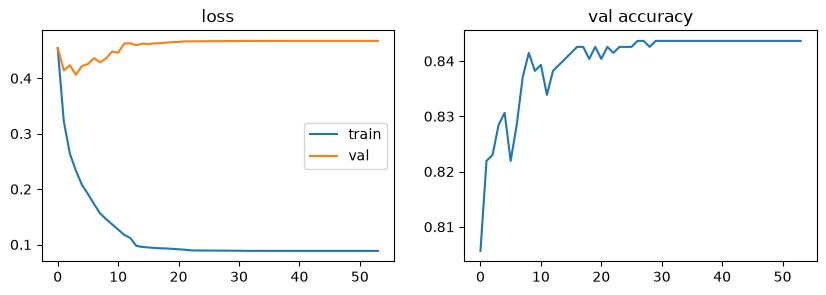

epochs:  26%|██▋       | 53/200 [00:17<00:47,  3.10it/s]

epoch 54: train 0.0885, val 0.4674, acc 0.8436
stopped at epoch 54
train acc: 0.932728111743927
val acc:   0.8284473419189453
train classes: [3358, 938]
val classes:   [700, 221]
test acc: 0.8610206246376038


In [42]:
# HYDRA (multivariate) + linear classifier, with progress bars and a live loss plot.
# Cells are separated by "# %%" (run them one by one in VS Code or paste into Jupyter cells).
#
# Expects these to exist before running (from make_split):
#   X_train, X_val, X_test : float32 tensors, shape (N, n_features, length)
#   y_train, y_val, y_test : integer class labels (tensors)

# %% imports
import copy
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import clear_output
from tqdm.auto import tqdm

# %% HydraMultivariate (Dempster, Schmidt, Webb - experimental multivariate version)
class HydraMultivariate(nn.Module):

    def __init__(self, input_length, num_channels, k=8, g=64, max_num_channels=8):

        super().__init__()

        self.k = k  # num kernels per group
        self.g = g  # num groups

        max_exponent = np.log2((input_length - 1) / (9 - 1))  # kernel length = 9

        self.dilations = 2 ** torch.arange(int(max_exponent) + 1)
        self.num_dilations = len(self.dilations)

        self.paddings = torch.div((9 - 1) * self.dilations, 2, rounding_mode="floor").int()

        # if g > 1, assign: half the groups to X, half the groups to diff(X)
        divisor = 2 if self.g > 1 else 1
        _g = g // divisor
        self._g = _g

        self.W = [self.normalize(torch.randn(divisor, k * _g, 1, 9)) for _ in range(self.num_dilations)]

        # combine num_channels // 2 channels (2 < n < max_num_channels)
        num_channels_per = np.clip(num_channels // 2, 2, max_num_channels)
        self.I = [torch.randint(0, num_channels, (divisor, _g, num_channels_per)) for _ in range(self.num_dilations)]

    @staticmethod
    def normalize(W):
        W -= W.mean(-1, keepdims=True)
        W /= W.abs().sum(-1, keepdims=True)
        return W

    def forward(self, X):

        num_examples = X.shape[0]

        if self.g > 1:
            diff_X = torch.diff(X)

        Z = []

        for dilation_index in range(self.num_dilations):

            d = self.dilations[dilation_index].item()
            p = self.paddings[dilation_index].item()

            # diff_index == 0 -> X
            # diff_index == 1 -> diff(X)
            for diff_index in range(min(2, self.g)):

                _Z = F.conv1d(X[:, self.I[dilation_index][diff_index]].sum(2) if diff_index == 0 else diff_X[:, self.I[dilation_index][diff_index]].sum(2),
                              self.W[dilation_index][diff_index], dilation=d, padding=p,
                              groups=self._g) \
                      .view(num_examples, self._g, self.k, -1)

                max_values, max_indices = _Z.max(2)
                count_max = torch.zeros(num_examples, self._g, self.k)

                min_values, min_indices = _Z.min(2)
                count_min = torch.zeros(num_examples, self._g, self.k)

                count_max.scatter_add_(-1, max_indices, max_values)
                count_min.scatter_add_(-1, min_indices, torch.ones_like(min_values))

                Z.append(count_max)
                Z.append(count_min)

        Z = torch.cat(Z, 1).view(num_examples, -1)

        return Z

# %% 1. standardize each channel with training statistics
y_train, y_val, y_test = y_train.long(), y_val.long(), y_test.long()

mu = X_train.mean(dim=(0, 2), keepdim=True)
sd = X_train.std(dim=(0, 2), keepdim=True) + 1e-8
X_train, X_val, X_test = [(x - mu) / sd for x in (X_train, X_val, X_test)]

# %% 2. HYDRA feature transform (with progress bar)
torch.manual_seed(0)
hydra = HydraMultivariate(input_length=X_train.shape[-1], num_channels=X_train.shape[1])

def features(X, batch_size=256):
    out = []
    with torch.no_grad():
        for i in tqdm(range(0, len(X), batch_size), desc="HYDRA features"):
            out.append(hydra(X[i:i + batch_size]).clamp(0).sqrt())
    return torch.cat(out)

Z_train, Z_val, Z_test = features(X_train), features(X_val), features(X_test)

# %% 3. scale features
f_mean = Z_train.mean(0)
f_std = Z_train.std(0) + (Z_train == 0).float().mean(0) ** 4 + 1e-8

def scale(Z):
    return ((Z - f_mean) * (Z != 0)) / f_std

S_train, S_val, S_test = scale(Z_train), scale(Z_val), scale(Z_test)

# %% 4. model, loss, optimizer
num_classes = int(y_train.max()) + 1
model = nn.Linear(S_train.shape[1], num_classes)
nn.init.zeros_(model.weight)
nn.init.zeros_(model.bias)

loss_fn = nn.CrossEntropyLoss()
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.1, patience=8)

batch_size, patience, max_epochs = 128, 50, 200

# %% 5. training loop (progress bar + live plot + early stopping)
train_losses, val_losses, val_accs = [], [], []
best_loss, best_state, stall = float("inf"), None, 0

for epoch in tqdm(range(max_epochs), desc="epochs"):

    model.train()
    running = 0.0
    for idx in torch.randperm(len(S_train)).split(batch_size):
        opt.zero_grad()
        loss = loss_fn(model(S_train[idx]), y_train[idx])
        loss.backward()
        opt.step()
        running += loss.item() * len(idx)
    train_losses.append(running / len(S_train))

    model.eval()
    with torch.no_grad():
        out = model(S_val)
        val_losses.append(loss_fn(out, y_val).item())
        val_accs.append((out.argmax(1) == y_val).float().mean().item())
    sched.step(val_losses[-1])

    # live plot
    clear_output(wait=True)
    fig, ax = plt.subplots(1, 2, figsize=(10, 3))
    ax[0].plot(train_losses, label="train")
    ax[0].plot(val_losses, label="val")
    ax[0].set_title("loss")
    ax[0].legend()
    ax[1].plot(val_accs)
    ax[1].set_title("val accuracy")
    plt.show()
    print(f"epoch {epoch + 1}: train {train_losses[-1]:.4f}, val {val_losses[-1]:.4f}, acc {val_accs[-1]:.4f}")
    
    # early stopping on validation loss
    if val_losses[-1] < best_loss - 1e-4:
        best_loss, best_state, stall = val_losses[-1], copy.deepcopy(model.state_dict()), 0
    else:
        stall += 1
        if stall >= patience:
            print(f"stopped at epoch {epoch + 1}")
            break

model.load_state_dict(best_state)  # restore the best epoch

with torch.no_grad():
    print("train acc:", (model(S_train).argmax(1) == y_train).float().mean().item())
    print("val acc:  ", (model(S_val).argmax(1) == y_val).float().mean().item())
print("train classes:", torch.bincount(y_train).tolist())
print("val classes:  ", torch.bincount(y_val).tolist())


# %% 6. final test score (used once)
model.eval()
with torch.no_grad():
    test_acc = (model(S_test).argmax(1) == y_test).float().mean().item()
print("test acc:", test_acc)



In [43]:
print(patience)

50


In [44]:
from sklearn.metrics import classification_report, confusion_matrix

model.eval()
with torch.no_grad():
    pred = model(S_val).argmax(1)
print(confusion_matrix(y_val, pred))
print(classification_report(y_val, pred))

[[661  39]
 [119 102]]
              precision    recall  f1-score   support

           0       0.85      0.94      0.89       700
           1       0.72      0.46      0.56       221

    accuracy                           0.83       921
   macro avg       0.79      0.70      0.73       921
weighted avg       0.82      0.83      0.81       921

